In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statistics as st

 Considera la base de datos AlumnosInferencia.xlsx y realiza lo siguiente:
- (a) Para cada una de las columnas especifica el tipo de variable y la escala de medición.
- (b) Realiza un análisis descriptivo de la variable promedio.
- (c) Compara descriptivamente la distribución de los promedios entre los dos turnos. ¿Qué diferencias o similitudes se observan? Justifica tu respuesta mediante medidas numéricas y/o
representaciones gráficas apropiadas.
- (d) Compara descriptivamente la distribución de los promedios entre géneros. ¿Qué diferencias
o similitudes se observan?
- (e) Compara descriptivamente la distribución de los promedios entre las diferentes carreras. ¿Qué
diferencias o similitudes se observan?

In [8]:
df = pd.read_excel("./data/AlumnosInferencia.xlsx", sheet_name='Sheet 1')

In [20]:
df.head(10)

,Edad,Genero,Carrera,Promedio,Foraneo,Turno
0,23,H,Aplicadas,8.19,1,V
1,24,H,Matemáticas,8.80,0,V
2,19,H,Actuaría,9.10,1,V
3,24,H,Matemáticas,9.30,0,V
4,21,H,Actuaría,8.70,0,V
5,24,H,Aplicadas,8.10,0,V
6,20,M,Aplicadas,8.70,0,V
7,22,M,Actuaría,8.90,0,V
8,21,M,Actuaría,9.20,0,V
9,19,M,Actuaría,9.80,0,V


In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 122 entries, 0 to 121
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Edad      122 non-null    int64  
 1   Genero    122 non-null    str    
 2   Carrera   122 non-null    str    
 3   Promedio  122 non-null    float64
 4   Foraneo   122 non-null    int64  
 5   Turno     122 non-null    str    
dtypes: float64(1), int64(2), str(3)
memory usage: 5.8 KB


## Análisis de las columnas en la base de datos
- **Edad**: Variable cuantitativa y escala de medición: Razón
- **Genero**: Variable categorica y escala de medición: nominal
- **Carrera**: Variable categorica y escala de medición: ordinal
- **Promedio**: Variable cuantitativa y escala de medición: Razón
- **Foraneo**: Variable categorica y escala de medición: nominal
- **Turno**: Variable categorica y escala de medición: ordinal

In [34]:
## valores unicos por variables categoricas
unique_values_genero = df["Genero"].unique()
print(f"Los valores unicos para el campo 'Genero' son: {unique_values_genero} ")
## =========================================== ##
unique_values_carrera = df["Carrera"].unique()
print(f"Los valores unicos para el campo 'Carrera' son: {unique_values_carrera} ")
## =========================================== ##
unique_values_foraneo = df["Foraneo"].unique()
print(f"Los valores unicos para el campo 'Foraneo' son: {unique_values_foraneo} ")
## =========================================== ##
unique_values_turno = df["Turno"].unique()
print(f"Los valores unicos para el campo 'Turno' son: {unique_values_turno} ")

Los valores unicos para el campo 'Genero' son: <StringArray>
['H', 'M']
Length: 2, dtype: str 
Los valores unicos para el campo 'Carrera' son: <StringArray>
['Aplicadas', 'Matemáticas', 'Actuaría', 'Matemático', 'Física', 'Compu']
Length: 6, dtype: str 
Los valores unicos para el campo 'Foraneo' son: [1 0] 
Los valores unicos para el campo 'Turno' son: <StringArray>
['V', 'M']
Length: 2, dtype: str 


In [17]:
df.describe()

,Edad,Promedio,Foraneo
count,122.000000,122.000000,122.000000
mean,21.163934,8.595820,0.204918
std,2.527079,0.480141,0.405306
min,19.000000,7.000000,0.000000
25%,20.000000,8.200000,0.000000
50%,20.000000,8.600000,0.000000
75%,22.000000,8.900000,0.000000
max,37.000000,9.800000,1.000000


In [47]:
#Análisis de la variable promedio
## obtención de medidas de tendencia central
#media
media_promedio = np.mean(df.Promedio)
print(f"media de mi varible 'Promedio' : {media_promedio}")
#mediana
mediana_promedio = np.median(df.Promedio)
print(f"mediana de mi varible 'Promedio' : {mediana_promedio}")
#moda
moda_promedio = st.mode(df.Promedio)
print(f"moda de mi varible 'Promedio' : {moda_promedio}")

media de mi varible 'Promedio' : 8.595819672131148
mediana de mi varible 'Promedio' : 8.6
moda de mi varible 'Promedio' : 8.0


In [55]:
#obtencion de cuartiles
# Obtener Q1, Q2 (mediana) y Q3 usando percentiles (0 a 100)
q1, q2, q3 = np.percentile(df.Promedio, [25, 50, 75])
print(f"Primer Cuartil (Q1): {q1}")
print(f"Segundo Cuartil (Q2/Mediana): {q2}")
print(f"Tercer Cuartil (Q3): {q3}")

Primer Cuartil (Q1): 8.2
Segundo Cuartil (Q2/Mediana): 8.6
Tercer Cuartil (Q3): 8.9


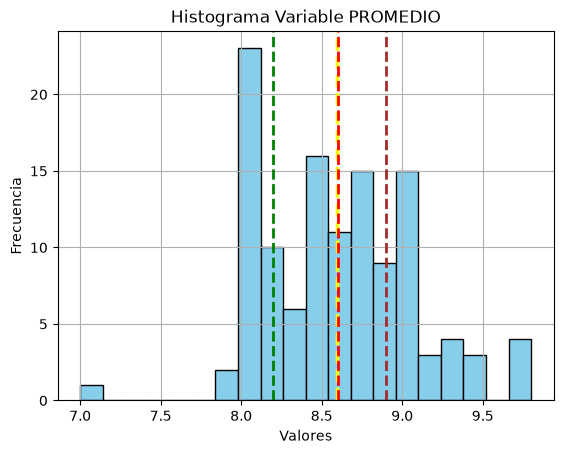

In [77]:
plt.hist(df.Promedio, bins= 20, color='skyblue', edgecolor='black')
plt.title("Histograma Variable PROMEDIO")
plt.xlabel('Valores')
plt.ylabel('Frecuencia')
plt.axvline(x=media_promedio, color='yellow', linestyle='--', linewidth=2.5)
plt.axvline(x=q1, color='green', linestyle='--', linewidth=2)
plt.axvline(x=q2, color='red', linestyle='--', linewidth=2)
plt.axvline(x=q3, color='brown', linestyle='--', linewidth=2)
plt.grid(True)
plt.show()

In [70]:
std_promedio = df.Promedio.std()
print(std_promedio)

## ==================##
var_promedio = df.Promedio.var()
print(var_promedio)

## ==================##
## coeficiente de variacion
cv = std_promedio/media_promedio
print(f"coeficiente de variacion: {cv}")

0.4801408886964729
0.2305352729982388
coeficiente de variacion: 0.05585748736134577


In [82]:
def coeficiente_asimetria(datos):
    avg_data = np.mean(datos)
    # Al restar un escalar a la Serie, la operación se aplica a todas las filas simultáneamente
    suma_cubos = ((datos - avg_data)**3).sum()
    return suma_cubos / (len(datos) * (datos.std(ddof=0)**3))

def coeficiente_curtosis(datos):
    avg_data = np.mean(datos)
    suma_cuartas = ((datos - avg_data)**4).sum()
    return (suma_cuartas / (len(datos) * (datos.std(ddof=0)**4))) - 3

print(f"coeficiente de asimetria para variable promedio: {coeficiente_asimetria(df['Promedio'])}")
print(f"coeficiente de curtosis para variable promedio: {coeficiente_curtosis(df['Promedio'])}")

coeficiente de asimetria para variable promedio: 0.19869675662135966
coeficiente de curtosis para variable promedio: 0.2742188696657166


In [83]:
print(df.Promedio.skew())
print(df.Promedio.kurtosis())

0.2011787625674863
0.3366386160528641


In [102]:
#Analsis de distribucion de promedios por turno
promedios_vespertino = df["Promedio"][df["Turno"] == 'V']
promedios_matutino = df["Promedio"][df["Turno"] == 'M']

In [103]:
promedios_matutino.describe()

count    80.000000
mean      8.579375
std       0.484463
min       7.000000
25%       8.200000
50%       8.600000
75%       8.900000
max       9.800000
Name: Promedio, dtype: float64

In [104]:
promedios_vespertino.describe()

count    42.000000
mean      8.627143
std       0.476016
min       7.900000
25%       8.200000
50%       8.650000
75%       8.937500
max       9.800000
Name: Promedio, dtype: float64

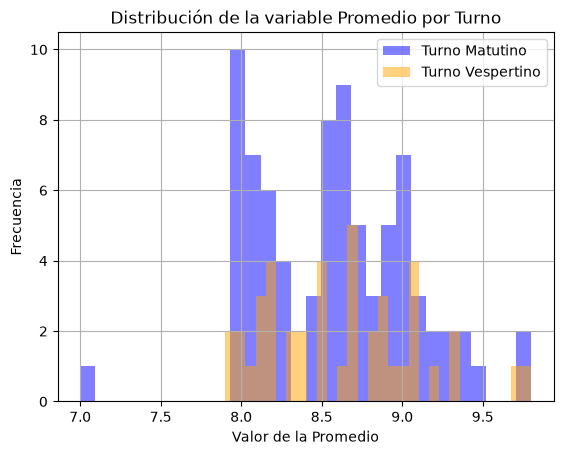

In [111]:
# 2. Dibujar ambos histogramas
plt.hist(promedios_matutino, bins=30, alpha=0.5, label='Turno Matutino', color='blue')
plt.hist(promedios_vespertino, bins=30, alpha=0.5, label='Turno Vespertino', color='orange')

# 3. Añadir detalles visuales
plt.title('Distribución de la variable Promedio por Turno')
plt.xlabel('Valor de la Promedio')
plt.ylabel('Frecuencia')
plt.legend(loc='upper right') # Muestra el cuadro de convenciones (leyenda)
plt.grid(True)
# 4. Renderizar el gráfico
plt.show()